In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(data)

In [3]:
df.head().T
df.columns = df.columns.str.lower().str.replace(" ", "_")

df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors="coerce")
df["totalcharges"] = df["totalcharges"].fillna(0)

categorical_columns = list(df.dtypes[df.dtypes == "str"].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(" ", "_")



df["churn"] = (df["churn"] == "yes").astype(int)


In [4]:
from sklearn.model_selection import train_test_split

train_full_df, test_df = train_test_split(df, test_size=0.2, random_state=1)

train_df, val_df = train_test_split(train_full_df, test_size=0.25, random_state=1)

len(train_df), len(val_df), len(test_df), len(df)

(4225, 1409, 1409, 7043)

In [5]:
y_train, y_val, y_test = train_df["churn"].values, val_df["churn"].values, test_df["churn"].values

del train_df["churn"]
del val_df["churn"]
del test_df["churn"]


In [6]:
y = train_full_df["churn"]
print(y.value_counts(normalize=True))
global_churn_rate = y.mean()
print(round(global_churn_rate, 2))

numerical_features = []
for c in train_full_df.columns:
    if c not in categorical_columns:
        numerical_features.append(c)
print(numerical_features)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64
0.27
['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']


In [7]:
# categorical_columns.remove("churn")
# categorical_columns.remove("customerid")
categorical_columns.append("seniorcitizen")

In [8]:

for c in categorical_columns:
    print(c)
    df_group = train_full_df.groupby(c)["churn"].agg(["mean", "count"])
    df_group["diff"] = df_group["mean"] - global_churn_rate
    df_group["rate"] = df_group["mean"]/global_churn_rate
    print(df_group.head())

customerid
            mean  count      diff      rate
customerid                                 
0002-orfbo   0.0      1 -0.269968  0.000000
0004-tlhlj   1.0      1  0.730032  3.704142
0011-igkff   1.0      1  0.730032  3.704142
0013-exchz   1.0      1  0.730032  3.704142
0013-mhzwf   0.0      1 -0.269968  0.000000
gender
            mean  count      diff      rate
gender                                     
female  0.276824   2796  0.006856  1.025396
male    0.263214   2838 -0.006755  0.974980
partner
             mean  count      diff      rate
partner                                     
no       0.329809   2932  0.059841  1.221659
yes      0.205033   2702 -0.064935  0.759472
dependents
                mean  count      diff      rate
dependents                                     
no          0.313760   3968  0.043792  1.162212
yes         0.165666   1666 -0.104302  0.613651
phoneservice
                  mean  count      diff      rate
phoneservice                                

In [9]:
from sklearn.metrics import mutual_info_score

mutual_info_score(train_full_df["churn"], train_full_df["contract"])

def mutual_info_score_churn(series):
    return mutual_info_score(train_full_df["churn"], series)

mutual_information = train_full_df[categorical_columns].apply(mutual_info_score_churn)
mutual_information.sort_values(ascending=False)

churn               0.583227
customerid          0.583227
contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [10]:
categorical_columns.remove("churn")
print(numerical_features)
print(categorical_columns)

train_full_df[numerical_features].corrwith(train_full_df["churn"])

['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']
['customerid', 'gender', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'seniorcitizen']


seniorcitizen     0.141966
tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [11]:
from sklearn.feature_extraction import DictVectorizer

train_dicts = train_df[numerical_features + categorical_columns].to_dict(orient="records")
val_dicts = val_df[numerical_features + categorical_columns].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

/tmp/ipykernel_2463/2723151081.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  train_dicts = train_df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/2723151081.py:4: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  val_dicts = val_df[numerical_features + categorical_columns].to_dict(orient="records")


In [12]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

In [13]:
print(y_train)

[0 0 1 ... 1 0 1]


In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [42]:
model.intercept_[0]
y_pred = model.predict_proba(X_val)[:, 1]
churn_decisions = (y_pred >= 0.5).astype(int)
print(churn_decisions)
print(y_val)
print((y_val == churn_decisions).mean())


[0 0 0 ... 0 1 1]
[0 0 0 ... 0 1 1]
0.7984386089425124


In [16]:
print((y_val == churn_decisions))

[ True  True  True ...  True  True  True]


In [17]:
df_pred = pd.DataFrame()
df_pred["probability"] = y_pred
df_pred["predictions"] = churn_decisions
df_pred["actual"] = y_val
print(df_pred)

      probability  predictions  actual
0        0.008438            0       0
1        0.213019            0       0
2        0.215351            0       0
3        0.527515            1       1
4        0.212817            0       0
...           ...          ...     ...
1404     0.341269            0       0
1405     0.038470            0       1
1406     0.134037            0       0
1407     0.801127            1       1
1408     0.840307            1       1

[1409 rows x 3 columns]


In [18]:
len(y_val)

1409

In [19]:
from sklearn.metrics import accuracy_score

[(np.float64(0.0), 0.2739531582682754), (np.float64(0.05), 0.5124201561391057), (np.float64(0.1), 0.5968772178850248), (np.float64(0.15000000000000002), 0.6678495386799148), (np.float64(0.2), 0.709013484740951), (np.float64(0.25), 0.7345635202271115), (np.float64(0.30000000000000004), 0.7551454932576295), (np.float64(0.35000000000000003), 0.7693399574166075), (np.float64(0.4), 0.7828246983676366), (np.float64(0.45), 0.7963094393186657), (np.float64(0.5), 0.7984386089425124), (np.float64(0.55), 0.8019872249822569), (np.float64(0.6000000000000001), 0.7955997161107168), (np.float64(0.65), 0.78708303761533), (np.float64(0.7000000000000001), 0.7636621717530163), (np.float64(0.75), 0.7452093683463449), (np.float64(0.8), 0.7352732434350603), (np.float64(0.8500000000000001), 0.7260468417317246), (np.float64(0.9), 0.7260468417317246), (np.float64(0.9500000000000001), 0.7260468417317246), (np.float64(1.0), 0.7260468417317246)]
(np.float64(0.55), 0.8019872249822569)


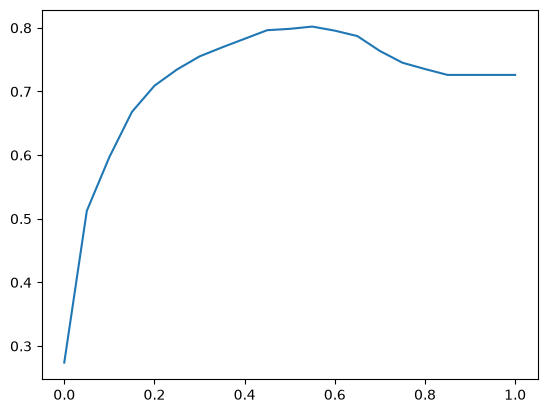

In [20]:
thresholds = np.linspace(0, 1, 21)
accuracies_pairs = []
for t in thresholds:
    churn_decisions = (y_pred >= t).astype(int)
    accuracies_pairs.append((t,accuracy_score(y_val, churn_decisions)))

print(accuracies_pairs)
accuracies = [t[1] for t in accuracies_pairs]

print(accuracies_pairs[accuracies.index(max(accuracies))])
plt.plot(thresholds, accuracies)
plt.show()



In [21]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

true_positive = ((actual_positive & predict_positive)).sum()
true_negative = ((actual_negative & predict_negative)).sum()
false_positive = ((actual_negative & predict_positive)).sum()
false_negative = ((actual_positive & predict_negative)).sum()

confusion_matrix = np.array([[true_negative, false_positive], [false_negative, true_positive]])
confusion_matrix = (confusion_matrix / confusion_matrix.sum()).round(2)
print(confusion_matrix)

[[0.65 0.08]
 [0.12 0.15]]


In [22]:
precision = true_positive / (true_positive + false_positive)

In [23]:
recall = true_positive / (true_positive + false_negative)

In [24]:
tpr = true_positive / (true_positive + false_negative)
fpr = false_positive / (true_negative + false_positive)

In [25]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

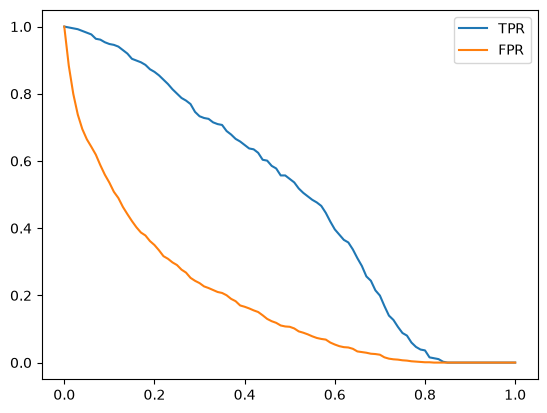

In [26]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [27]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

0.8423335815112517


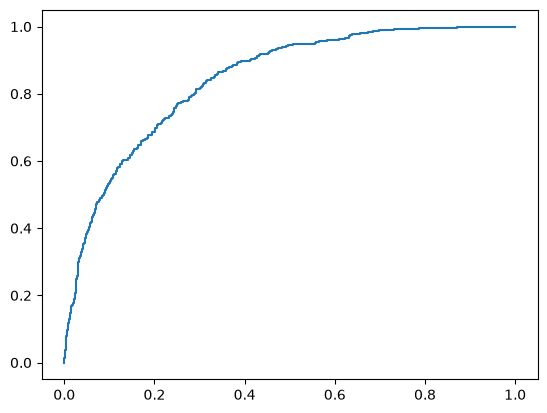

In [43]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

plt.plot(fpr, tpr)
print(auc(fpr, tpr))

In [61]:
def train(df_train, y_train, C=1.0):

    df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_train)

    model = LogisticRegression(C=C)
    model.fit(X, y_train)

    return dv, model

In [50]:
dv, model = train(train_df, y_train)

/tmp/ipykernel_2463/1897775309.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [51]:
def predict(dv, model, df):
    dict = df[numerical_features + categorical_columns].to_dict(orient="records")
    X = dv.transform(dict)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [52]:
print(predict(dv, model, val_df))

[0.04108743 0.02148235 0.06143241 0.03263252 0.08591509 0.13894091
 0.10985908 0.33125694 0.32799858 0.06841883 0.66665579 0.31349151
 0.06160929 0.20833385 0.22798096 0.00623932 0.12491163 0.01921429
 0.19377562 0.11024019 0.00330029 0.28370465 0.0162634  0.08091992
 0.12974762 0.51772276 0.15326206 0.65780285 0.03903752 0.00218903
 0.32186383 0.02832406 0.09404073 0.70136897 0.04797116 0.55370456
 0.06925445 0.00893397 0.03835352 0.01936488 0.73913728 0.09139924
 0.19424938 0.64368673 0.10387398 0.01382999 0.07354882 0.64490954
 0.38690959 0.05704861 0.62897157 0.4645357  0.02052303 0.778979
 0.76114915 0.45346099 0.00201837 0.04073191 0.13290873 0.42947584
 0.00521506 0.10822062 0.21335579 0.02944185 0.20183427 0.67892981
 0.17721823 0.39915394 0.60253627 0.76267219 0.5122829  0.44526765
 0.20760737 0.00451895 0.51162295 0.05052273 0.12766599 0.1963816
 0.25598566 0.20012806 0.08778947 0.63734938 0.52668005 0.01543257
 0.06811139 0.00689022 0.54976198 0.13222424 0.36755217 0.0105996

/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")


In [55]:
!pip install tqdm

In [64]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm


kfold = KFold(n_splits=5, shuffle=True, random_state=1)
for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    scores = []
    for train_idx, val_idx in kfold.split(train_full_df):
        train_df = train_full_df.iloc[train_idx]
        val_df = train_full_df.iloc[val_idx]

        y_train = train_df["churn"].values
        y_val = val_df["churn"].values

        dv, model = train(train_df, y_train, C=C)
        y_pred = predict(dv, model, val_df)

        scores.append(roc_auc_score(y_val, y_pred))
    print(f"{C} Mean: {np.mean(scores)}  SD: {np.std(scores)}")
        



  0%|          | 0/7 [00:00<?, ?it/s]

/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tm

0.001 Mean: 0.8260993427153634  SD: 0.011253297671800448


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

0.01 Mean: 0.8401060958710845  SD: 0.008853680958064186


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

0.1 Mean: 0.83965921986815  SD: 0.006713234816035215


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

0.5 Mean: 0.839595762102695  SD: 0.008622945194084726


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

1 Mean: 0.8406902209754566  SD: 0.008754654754798006


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

5 Mean: 0.8391461716179351  SD: 0.00730002291869074


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")
/us

10 Mean: 0.8396538403651579  SD: 0.007363210392730207


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")


In [65]:
C = 1

dv, model = train(train_full_df, train_full_df["churn"].values, C=C)
y_pred = predict(dv, model, test_df)
print(roc_auc_score(y_test, y_pred))

/tmp/ipykernel_2463/3224669784.py:3: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  df_train = df_train[numerical_features + categorical_columns].to_dict(orient="records")


0.8562256925260272


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_2463/3248985610.py:2: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  dict = df[numerical_features + categorical_columns].to_dict(orient="records")
